# UPI Fraud Detection - Analysis & Modelling Notebook

**Goal:** flag fraudulent UPI payments in real time while keeping friction for genuine users low.

**Success criteria (decided before modelling):**
1. *Ranking quality under heavy imbalance* -> PR-AUC and recall at a fixed flag rate (accuracy is useless at ~1% fraud).
2. *Business cost* -> a missed Rs 50k fraud and a wrongly blocked Rs 100 payment are not equal errors.
3. *Trustworthiness* -> calibrated probabilities, explainable reasons, no leakage, stable over time.

**Data:** simulated (real UPI data is not public) - 91 days, ~740k payments, 12k customers, 700 merchants in 13 categories, 12 cities, **8 labelled fraud typologies** *plus* hard legitimate look-alikes (big purchases, new phones, trips, rent, festival gifting).
This notebook answers the questions an interviewer would ask: *why this validation scheme? why not rules? what matters most? where does it fail?*

In [1]:
import sys, os, json, warnings
sys.path.insert(0, os.path.abspath(".."))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt
from lightgbm import LGBMClassifier
from sklearn.ensemble import IsolationForest
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss, precision_recall_curve
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from src.config import LGBM_PARAMS, MODELS, DATA
from src.dataset import load_modeling_data
from src.features import FEATURES, FRIENDLY
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25})
RESULTS = {}

df, data = load_modeling_data()
tr, va, te = (data[data.split == s] for s in ("train", "val", "test"))
print(f"raw {len(df):,} rows | modelling table {len(data):,} (after 14-day warm-up)")
print(f"train {len(tr):,} | val {len(va):,} | test {len(te):,}")
print(f"fraud rate: train {tr.is_fraud.mean():.2%} | test {te.is_fraud.mean():.2%}")

2026-10-31 06:42:23,546 | INFO | dataset | excluded 14-day warm-up; 628037 rows remain


raw 741,063 rows | modelling table 628,037 (after 14-day warm-up)
train 376,823 | val 94,205 | test 157,009
fraud rate: train 1.57% | test 1.75%


## 1. Exploratory analysis
What does fraud look like, and is the problem separable by simple signals?

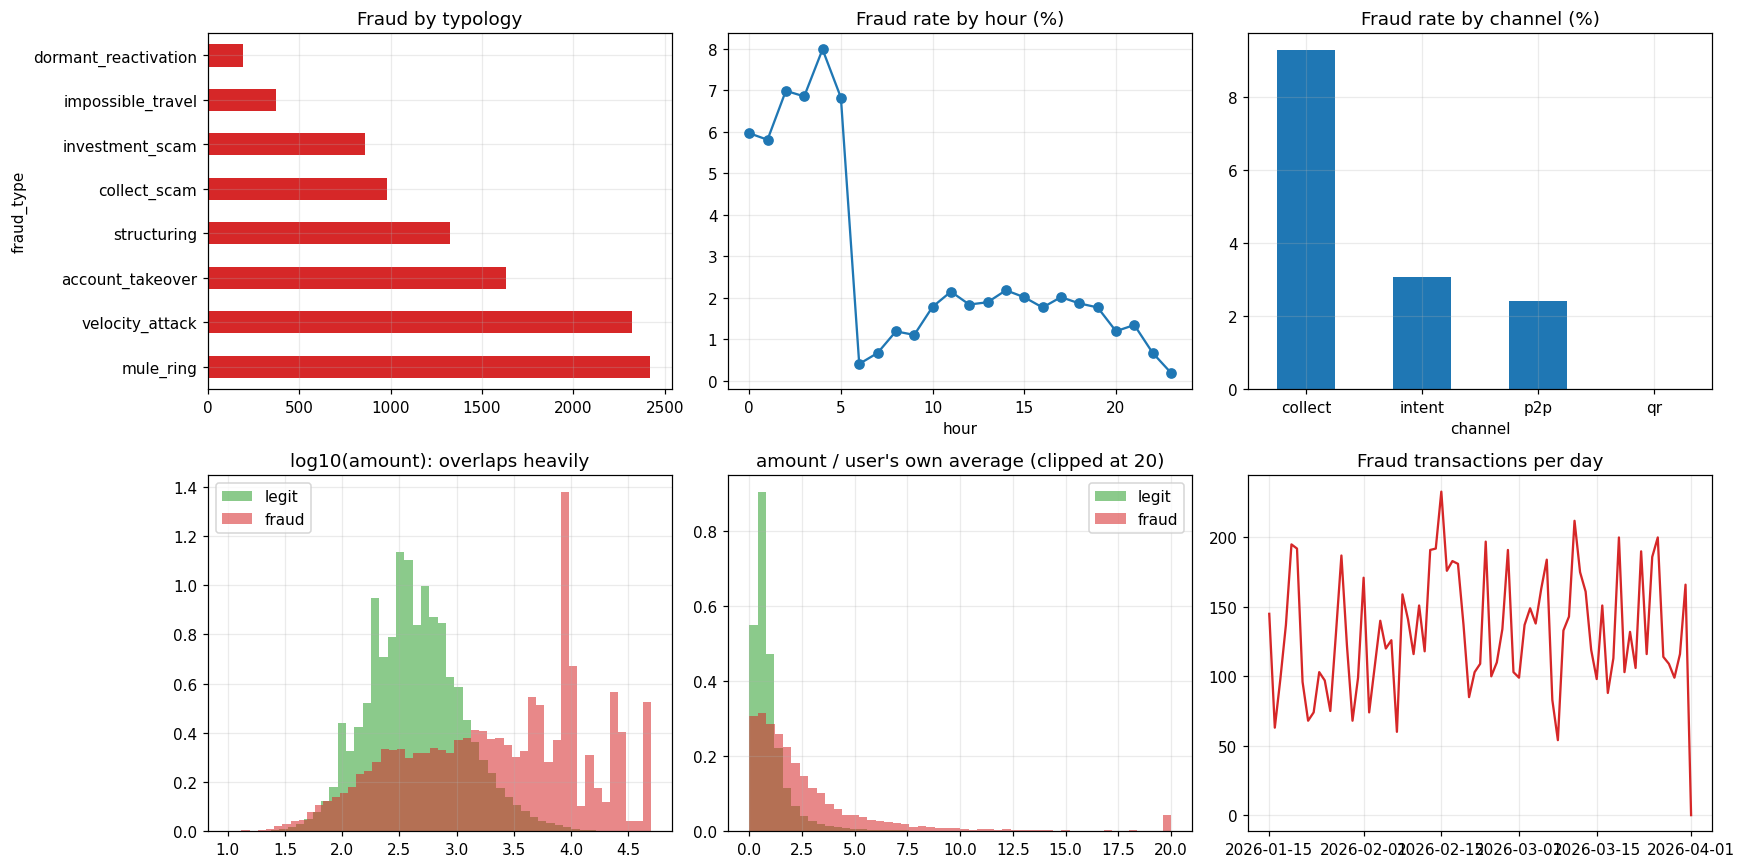

Takeaway: raw amount is informative but the two classes overlap heavily; real separation comes from combining it with behaviour (velocity, gaps, payee novelty, geography, account age).


In [2]:
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
data[data.is_fraud == 1].fraud_type.value_counts().plot.barh(ax=ax[0, 0], color="#d62728"); ax[0, 0].set_title("Fraud by typology")
(data.groupby("hour").is_fraud.mean() * 100).plot(ax=ax[0, 1], marker="o"); ax[0, 1].set_title("Fraud rate by hour (%)"); ax[0, 1].set_xlabel("hour")
(data.groupby("channel").is_fraud.mean() * 100).plot.bar(ax=ax[0, 2], color="#1f77b4"); ax[0, 2].set_title("Fraud rate by channel (%)"); ax[0, 2].tick_params(axis="x", rotation=0)
for lab, g, c in [("legit", data[data.is_fraud == 0], "#2ca02c"), ("fraud", data[data.is_fraud == 1], "#d62728")]:
    ax[1, 0].hist(np.log10(g.amount), bins=50, alpha=.55, density=True, label=lab, color=c)
    ax[1, 1].hist(g.amount_ratio.clip(0, 20), bins=50, alpha=.55, density=True, label=lab, color=c)
ax[1, 0].set_title("log10(amount): overlaps heavily"); ax[1, 0].legend()
ax[1, 1].set_title("amount / user's own average (clipped at 20)"); ax[1, 1].legend()
d = data.set_index("timestamp").resample("D").agg(n=("amount", "size"), fraud=("is_fraud", "sum"))
ax[1, 2].plot(d.index, d.fraud, color="#d62728"); ax[1, 2].set_title("Fraud transactions per day")
plt.tight_layout(); plt.show()
print("Takeaway: raw amount is informative but the two classes overlap heavily; real separation comes from combining it with behaviour (velocity, gaps, payee novelty, geography, account age).")

### 1.1 Univariate signal per feature
Single-feature ROC-AUC (0.5 = useless). This guides feature engineering and sanity-checks for suspiciously strong leaks.

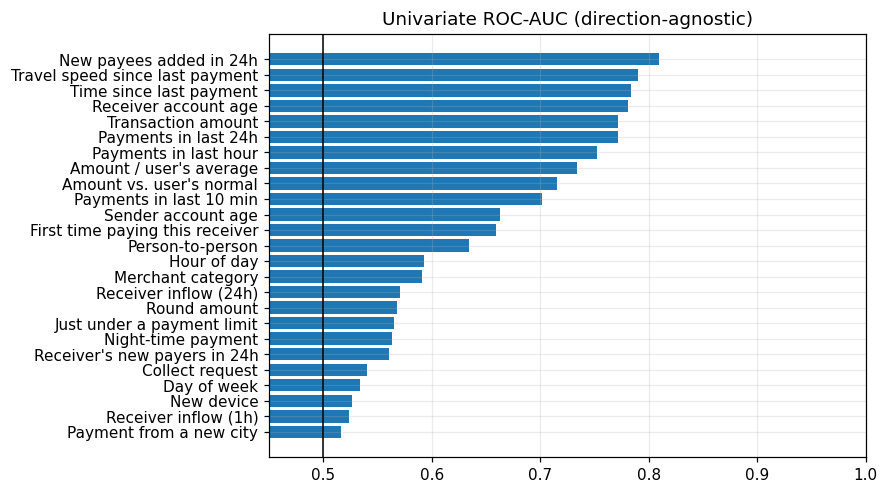

Best single feature AUC = 0.81; raw amount 0.77. Nothing near 1.0 -> no obvious target leak, and no single signal suffices: the model must combine them.
sender_new_rcv_24h    0.809
geo_speed_log         0.790
log_time_gap          0.784
recv_acct_age_log     0.781
log_amount            0.772


In [3]:
uni = pd.Series({f: roc_auc_score(data.is_fraud, data[f]) for f in FEATURES})
uni = (uni - .5).abs().add(.5).sort_values()          # direction-agnostic
fig, ax = plt.subplots(figsize=(7, 5)); ax.barh([FRIENDLY[i] for i in uni.index], uni.values, color="#1f77b4")
ax.axvline(.5, color="k", lw=1); ax.set_xlim(.45, 1); ax.set_title("Univariate ROC-AUC (direction-agnostic)"); plt.show()
print(f"Best single feature AUC = {uni.max():.2f}; raw amount {roc_auc_score(data.is_fraud, data.log_amount):.2f}. "
      "Nothing near 1.0 -> no obvious target leak, and no single signal suffices: the model must combine them.")
print(uni.round(3).sort_values(ascending=False).head(5).to_string())

## 2. Validation strategy: random split vs. time-based split
Behavioural data is sequential. A random split can let the model train on a user's *future* and on other legs of the *same fraud incident* (bursts, rings),
which can inflate scores. I use **chronological** splits and here I *measure* whether a random split would have flattered the model.

**Result to expect:** a small inflation in this stationary simulated world (features use only past data and behaviour does not change over time), and a much larger one on real data - notebook 2 measures +0.069 PR-AUC on the credit-card dataset. Time-based validation is the only defensible estimate either way.

In [4]:
def fit_eval(train, test, feats=FEATURES, **kw):
    m = LGBMClassifier(**{**LGBM_PARAMS, **kw}).fit(train[feats], train.is_fraud)
    p = m.predict_proba(test[feats])[:, 1]
    return m, p, average_precision_score(test.is_fraud, p), roc_auc_score(test.is_fraud, p)

dev, test = data[data.split != "test"], te
_, _, ap_time, auc_time = fit_eval(dev, test)                                    # honest: past -> future
rnd_tr, rnd_te = train_test_split(data, test_size=len(te) / len(data), stratify=data.is_fraud, random_state=0)
_, _, ap_rand, auc_rand = fit_eval(rnd_tr, rnd_te)                              # flattering: shuffled
split_tbl = pd.DataFrame({"PR-AUC": [ap_rand, ap_time], "ROC-AUC": [auc_rand, auc_time]}, index=["random split", "time-based split"]).round(4)
RESULTS["split_comparison"] = split_tbl.to_dict()
display(split_tbl)
print(f"Random minus time-based PR-AUC = {ap_rand - ap_time:+.3f}  -> a random split flatters the score modestly even in this stationary simulated world (real data: +0.069, notebook 2).")
print("I still report the time-based number: it mirrors deployment (train on the past, score the future) and is what drift would erode first.")

,PR-AUC,ROC-AUC
random split,0.9635,0.9987
time-based split,0.9485,0.9979


Random minus time-based PR-AUC = +0.015  -> a random split flatters the score modestly even in this stationary simulated world (real data: +0.069, notebook 2).
I still report the time-based number: it mirrors deployment (train on the past, score the future) and is what drift would erode first.


## 3. Baselines: would a rule engine already do the job?
Banks traditionally use hand-written rules. A fair evaluation must beat a *reasonable* rule set, not a straw man.

Rules flag 1.38% of payments -> recall 28%. LightGBM at the SAME flag rate -> recall 77%.


,PR_AUC,ROC_AUC,recall @ same flag rate as rules,precision @ same flag rate
model,,,,
LightGBM,0.945,0.998,0.768,0.974
Logistic regression,0.691,0.984,0.533,0.676
Isolation Forest (unsup.),0.443,0.962,0.356,0.451
Hand-written rules,NaN,NaN,0.276,0.350


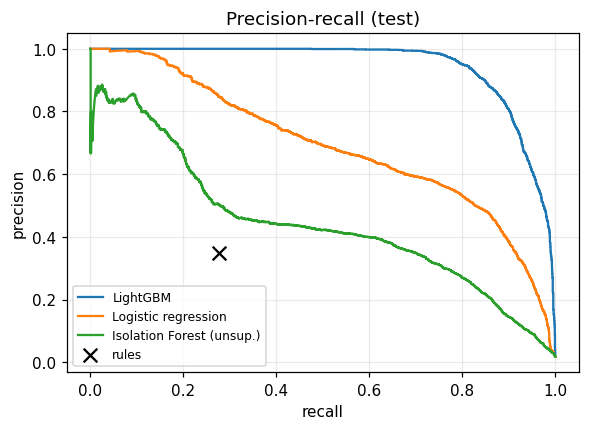

In [5]:
rule = lambda d: ((d.amount_ratio > 4) & (d.new_receiver == 1)) | (d.sender_cnt_10m >= 6) | ((d.is_night == 1) & (d.new_device == 1) & (d.amount_ratio > 2))
flag = rule(te).to_numpy()
rule_stats = dict(flag_rate=flag.mean(), precision=te.is_fraud[flag].mean(), recall=te.is_fraud[flag].sum() / te.is_fraud.sum())

def recall_at_rate(y, s, rate):
    k = max(1, int(rate * len(y))); idx = np.argsort(-s)[:k]
    return y[idx].sum() / y.sum(), y[idx].mean()

y_te = te.is_fraud.to_numpy()
m_lgb, p_lgb, *_ = fit_eval(tr, te)
lr = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000)).fit(tr[FEATURES], tr.is_fraud)
iso = IsolationForest(n_estimators=200, random_state=7, n_jobs=-1).fit(tr[FEATURES])
scores = {"LightGBM": p_lgb, "Logistic regression": lr.predict_proba(te[FEATURES])[:, 1], "Isolation Forest (unsup.)": -iso.score_samples(te[FEATURES])}
rows = []
for k, s in scores.items():
    r, p = recall_at_rate(y_te, s, rule_stats["flag_rate"])
    rows.append(dict(model=k, PR_AUC=average_precision_score(y_te, s), ROC_AUC=roc_auc_score(y_te, s), **{"recall @ same flag rate as rules": r, "precision @ same flag rate": p}))
rows.append(dict(model="Hand-written rules", PR_AUC=np.nan, ROC_AUC=np.nan, **{"recall @ same flag rate as rules": rule_stats["recall"], "precision @ same flag rate": rule_stats["precision"]}))
base_tbl = pd.DataFrame(rows).set_index("model").round(3)
print(f"Rules flag {rule_stats['flag_rate']:.2%} of payments -> recall {rule_stats['recall']:.0%}. LightGBM at the SAME flag rate -> recall {base_tbl.loc['LightGBM'].iloc[2]:.0%}.")
RESULTS["baselines"] = base_tbl.fillna(-1).to_dict("index")
display(base_tbl)
fig, ax = plt.subplots(figsize=(6, 4))
for k, s in scores.items():
    pr, rc, _ = precision_recall_curve(y_te, s); ax.plot(rc, pr, label=k)
ax.scatter([rule_stats["recall"]], [rule_stats["precision"]], c="k", marker="x", s=80, label="rules"); ax.set(xlabel="recall", ylabel="precision", title="Precision-recall (test)"); ax.legend(fontsize=8); plt.show()

## 4. Handling class imbalance
Fraud is ~1% of rows. Options: do nothing, re-weight, or undersample. I compare them on PR-AUC *and* Brier score (probability quality),
because re-weighting can help ranking while wrecking calibration.

In [6]:
res = {}
def imbalance_run(name, train, **kw):
    m = LGBMClassifier(**{**LGBM_PARAMS, **kw}).fit(train[FEATURES], train.is_fraud)
    p = m.predict_proba(te[FEATURES])[:, 1]
    res[name] = dict(PR_AUC=average_precision_score(y_te, p), recall_at_2pct_flag=recall_at_rate(y_te, p, .02)[0], Brier=brier_score_loss(y_te, p))
imbalance_run("no re-weighting (chosen)", tr)
imbalance_run("is_unbalance=True", tr, is_unbalance=True)
imbalance_run("scale_pos_weight=10", tr, scale_pos_weight=10)
neg, pos = tr[tr.is_fraud == 0], tr[tr.is_fraud == 1]
imbalance_run("undersample negatives 10:1", pd.concat([neg.sample(len(pos) * 10, random_state=0), pos]))
imb_tbl = pd.DataFrame(res).T.round(4); RESULTS["imbalance"] = imb_tbl.to_dict("index"); display(imb_tbl)
print(f"PR-AUC across strategies spans only {imb_tbl.PR_AUC.min():.3f}-{imb_tbl.PR_AUC.max():.3f} (differences of this size are within run-to-run noise), "
      f"while Brier score worsens from {imb_tbl.Brier.iloc[0]:.4f} to as much as {imb_tbl.Brier.max():.4f}.")
print("-> keep the natural class balance (better-behaved probabilities), then calibrate and choose thresholds on cost.")

,PR_AUC,recall_at_2pct_flag,Brier
no re-weighting (chosen),0.9450,0.9052,0.0033
is_unbalance=True,0.9377,0.8943,0.0074
scale_pos_weight=10,0.9427,0.8968,0.0043
undersample negatives 10:1,0.9396,0.8950,0.0046


PR-AUC across strategies spans only 0.938-0.945 (differences of this size are within run-to-run noise), while Brier score worsens from 0.0033 to as much as 0.0074.
-> keep the natural class balance (better-behaved probabilities), then calibrate and choose thresholds on cost.


## 5. Ablation: which feature groups earn their keep?
Drop one group at a time and retrain. Large drops = the group carries unique signal.

,PR_AUC,delta_vs_full
group_removed,,
sender velocity / gaps,0.8945,-0.0505
merchant category & channel,0.9028,-0.0422
amount vs. user history,0.9251,-0.0199
account age,0.9292,-0.0157
receiver behaviour / fan-in,0.9332,-0.0117
geography & device,0.9352,-0.0098
time of day / week,0.9398,-0.0052


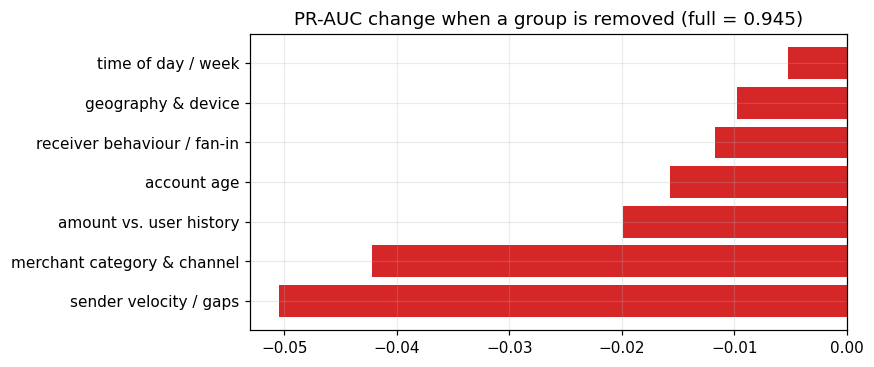

Most valuable group: 'sender velocity / gaps' (-0.051). Every group contributes, so none is dead weight.
Caveat: groups are correlated, so single-group drops understate shared signal; this is a guide, not a precise attribution.


In [7]:
groups = {
    "amount vs. user history": ["log_amount", "amount_z", "amount_ratio", "is_round", "near_limit"],
    "sender velocity / gaps": ["sender_cnt_10m", "sender_cnt_1h", "sender_cnt_24h", "log_time_gap", "sender_new_rcv_24h"],
    "receiver behaviour / fan-in": ["recv_cnt_1h", "recv_cnt_24h", "new_receiver", "recv_new_payers_24h"],
    "geography & device": ["geo_speed_log", "new_city", "new_device"],
    "account age": ["recv_acct_age_log", "sender_acct_age_log"],
    "merchant category & channel": ["merch_cat", "is_p2p", "is_collect"],
    "time of day / week": ["hour", "is_night", "dow"],
}
_, _, full_ap, _ = fit_eval(tr, te)
abl = []
for g, cols in groups.items():
    f = [c for c in FEATURES if c not in cols]
    _, _, ap, _ = fit_eval(tr, te, feats=f)
    abl.append(dict(group_removed=g, PR_AUC=ap, delta_vs_full=ap - full_ap))
abl = pd.DataFrame(abl).set_index("group_removed").sort_values("delta_vs_full").round(4)
RESULTS["ablation"] = dict(full_pr_auc=round(full_ap, 4), drops=abl.delta_vs_full.to_dict())
display(abl)
fig, ax = plt.subplots(figsize=(7, 3.5)); ax.barh(abl.index, abl.delta_vs_full, color="#d62728"); ax.set_title(f"PR-AUC change when a group is removed (full = {full_ap:.3f})"); plt.show()
print(f"Most valuable group: '{abl.index[0]}' ({abl.delta_vs_full.iloc[0]:+.3f}). Every group contributes, so none is dead weight.")
print("Caveat: groups are correlated, so single-group drops understate shared signal; this is a guide, not a precise attribution.")

## 6. Final model: calibration, operating point and explanations
The shipped pipeline (`src/train.py`) adds Platt calibration and chooses tier thresholds by minimising expected rupee cost.
Here I inspect its outputs on the untouched test period.

thresholds: {'step_up': 0.0054, 'review': 0.3808, 'block': 0.6015}
                    count  fraud_in_bucket
APPROVE            149949               32
STEP_UP_AUTH         4430              370
REVIEW                329              151
BLOCK_TRANSACTION    2301             2190


,prob bin,predicted,observed,n
0,0,0.0001,0.0001,144643
1,1,0.0028,0.0047,6147
2,2,0.0240,0.0465,1827
3,3,0.1086,0.1069,1282
4,4,0.3257,0.3213,663
5,5,0.6374,0.5877,359
6,6,0.9807,0.9842,2088


,flag_rate,recall,precision
0,0.002,0.114,1.000
1,0.005,0.286,1.000
2,0.010,0.571,0.998
3,0.020,0.905,0.791
4,0.030,0.962,0.560
5,0.050,0.991,0.346
6,0.100,0.996,0.174


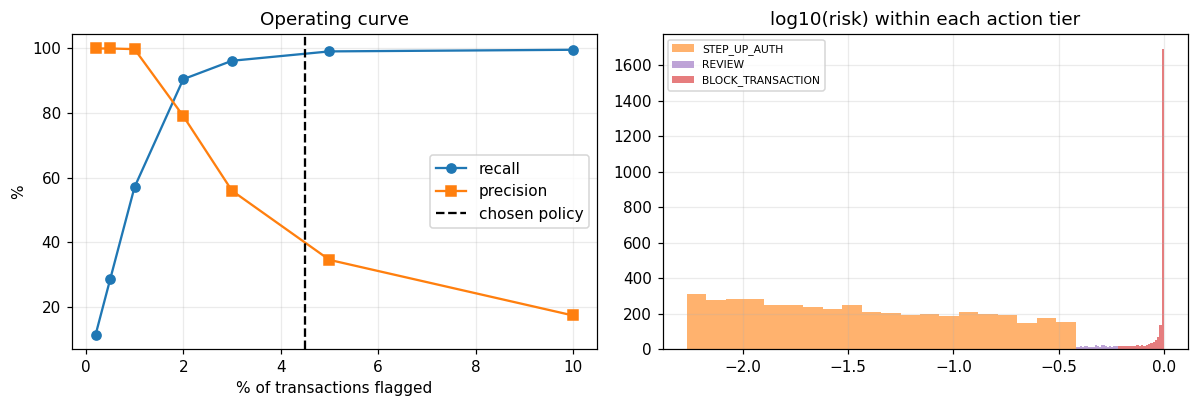

In [8]:
art = joblib.load(MODELS / "artifacts.joblib")
scored = pd.read_parquet(DATA / "scored.parquet"); st = scored[scored.split == "test"].copy()
M = json.load(open("../reports/metrics.json"))
print("thresholds:", {k: round(v, 4) for k, v in art["thresholds"].items()})
print(pd.DataFrame(M["test_decisions"]).T)
rel = pd.DataFrame(M["calibration"]["reliability"])
display(rel.round(4).rename(columns={"b": "prob bin"}))
y, s = st.is_fraud.to_numpy(), st.risk_score.to_numpy()
rates = np.array([.002, .005, .01, .02, .03, .05, .10])
curve = pd.DataFrame([dict(flag_rate=r, recall=recall_at_rate(y, s, r)[0], precision=recall_at_rate(y, s, r)[1]) for r in rates]).round(3)
display(curve); RESULTS["recall_at_flag_rate"] = curve.set_index("flag_rate").to_dict("index")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(curve.flag_rate * 100, curve.recall * 100, "o-", label="recall"); ax[0].plot(curve.flag_rate * 100, curve.precision * 100, "s-", label="precision")
ax[0].axvline(M["business_impact_test"]["flag_rate"] * 100, color="k", ls="--", label="chosen policy"); ax[0].set(xlabel="% of transactions flagged", ylabel="%", title="Operating curve"); ax[0].legend()
for t, c in zip(["STEP_UP_AUTH", "REVIEW", "BLOCK_TRANSACTION"], ["#ff7f0e", "#9467bd", "#d62728"]):
    ax[1].hist(np.log10(st[st.decision == t].risk_score), bins=20, alpha=.6, label=t, color=c)
ax[1].set_title("log10(risk) within each action tier"); ax[1].legend(fontsize=7); plt.tight_layout(); plt.show()

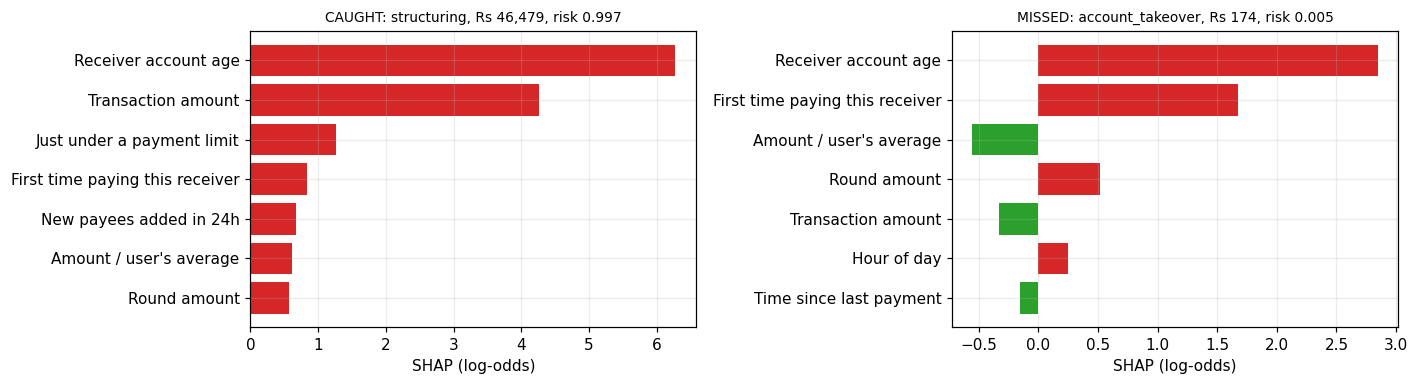

In [9]:
# Local explanations: one caught fraud vs. one missed fraud
def explain_row(r, top=7):
    c = art["lgbm"].booster_.predict(pd.DataFrame([r[FEATURES]]).astype(float), pred_contrib=True)[0][:-1]
    s = pd.Series(c, [FRIENDLY[f] for f in FEATURES]); return s.reindex(s.abs().sort_values(ascending=False).index[:top])[::-1]
caught = st[(st.is_fraud == 1) & (st.decision == "BLOCK_TRANSACTION")].sort_values("risk_score").iloc[len(st[(st.is_fraud == 1) & (st.decision == "BLOCK_TRANSACTION")]) // 2]
missed = st[(st.is_fraud == 1) & (st.decision == "APPROVE")].sort_values("risk_score", ascending=False).iloc[0]
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
for a, r, t in [(ax[0], caught, "CAUGHT"), (ax[1], missed, "MISSED")]:
    e = explain_row(r); a.barh(e.index, e.values, color=["#d62728" if v > 0 else "#2ca02c" for v in e.values])
    a.set_title(f"{t}: {r.fraud_type}, Rs {r.amount:,.0f}, risk {r.risk_score:.3f}", fontsize=9); a.set_xlabel("SHAP (log-odds)")
plt.tight_layout(); plt.show()

## 7. Error analysis: where does it fail?
Aggregate metrics hide *which* fraud slips through and *whom* we annoy. Both matter for a production decision.

In [10]:
fn = st[(st.is_fraud == 1) & (st.decision == "APPROVE")]
print(f"Missed fraud (APPROVE): {len(fn)} of {int(st.is_fraud.sum())}")
display(fn.groupby("fraud_type").agg(missed=("amount", "size"), avg_amount=("amount", "mean"), avg_risk=("risk_score", "mean")).round(3))
display(fn[["fraud_type", "amount", "channel", "hour", "amount_ratio", "new_receiver", "new_device", "sender_cnt_10m", "risk_score"]].round(2).head(8))
print(f"Of the missed frauds: {(fn.sender_cnt_10m == 0).mean():.0%} had NO prior payment in the last 10 min, {(fn.amount_ratio < 1).mean():.0%} were below the user's average amount.")
vel = st[st.fraud_type == "velocity_attack"]
pos = vel.groupby(np.where(vel.sender_cnt_10m == 0, "1st payment of burst", "later payments")).decision.apply(lambda d: (d != "APPROVE").mean()).round(3)
print("Velocity-attack recall by position in burst:"); print(pos.to_string())
fp = st[(st.is_fraud == 0) & (st.decision.isin(["REVIEW", "BLOCK_TRANSACTION"]))]
base = st[st.is_fraud == 0]
cmp = pd.DataFrame({"flagged genuine": [fp.new_receiver.mean(), (fp.amount_ratio > 3).mean(), fp.is_night.mean(), (fp.sender_cnt_10m >= 4).mean(), fp.is_collect.mean()],
                    "all genuine": [base.new_receiver.mean(), (base.amount_ratio > 3).mean(), base.is_night.mean(), (base.sender_cnt_10m >= 4).mean(), base.is_collect.mean()]},
                   index=["new receiver", "amount > 3x usual", "night", ">=4 payments / 10 min", "collect request"]).round(3)
print(f"\nGenuine payments sent to REVIEW/BLOCK: {len(fp)} ({len(fp) / len(base):.2%} of genuine traffic)")
display(cmp)
RESULTS["error_analysis"] = dict(missed_fraud=int(len(fn)), missed_by_type=fn.fraud_type.value_counts().to_dict(), genuine_flagged=int(len(fp)), genuine_flag_pct=round(len(fp) / len(base), 5))
print("Reading: flagged-genuine payments are dominated by NEW payees, amounts far above the user's norm, bursts and collect requests - the look-alikes I injected.")
print("They are indistinguishable from fraud on these features alone, which is why REVIEW (human) and STEP_UP (cheap friction) tiers exist.")
print("Almost all misses are the FIRST leg of an attack (percentages above): a per-transaction scorer cannot see a burst that has not started. Fix = policy (limits / cooling-off for new payees) or receiver-side graph signals.")

Missed fraud (APPROVE): 32 of 2743


,missed,avg_amount,avg_risk
fraud_type,,,
account_takeover,2,332.420013,0.005
collect_scam,1,264.709991,0.004
velocity_attack,29,391.183990,0.002


,fraud_type,amount,channel,hour,amount_ratio,new_receiver,new_device,sender_cnt_10m,risk_score
480175,velocity_attack,552.739990,intent,8,0.56,1,0,0,0.0
481334,velocity_attack,288.709991,intent,11,0.47,1,1,0,0.0
482502,velocity_attack,740.369995,intent,14,0.85,1,1,0,0.0
483108,velocity_attack,65.139999,intent,16,0.21,1,0,0,0.0
488939,velocity_attack,535.929993,intent,11,0.41,0,0,0,0.0
492875,velocity_attack,287.480011,intent,19,0.26,1,0,0,0.0
505926,velocity_attack,171.380005,intent,11,0.45,1,1,0,0.0
509589,velocity_attack,185.250000,intent,21,0.25,1,0,0,0.0


Of the missed frauds: 94% had NO prior payment in the last 10 min, 100% were below the user's average amount.
Velocity-attack recall by position in burst:
1st payment of burst    0.518
later payments          0.997

Genuine payments sent to REVIEW/BLOCK: 289 (0.19% of genuine traffic)


,flagged genuine,all genuine
new receiver,0.592,0.180
amount > 3x usual,0.353,0.038
night,0.007,0.037
>=4 payments / 10 min,0.111,0.007
collect request,0.194,0.015


Reading: flagged-genuine payments are dominated by NEW payees, amounts far above the user's norm, bursts and collect requests - the look-alikes I injected.
They are indistinguishable from fraud on these features alone, which is why REVIEW (human) and STEP_UP (cheap friction) tiers exist.
Almost all misses are the FIRST leg of an attack (percentages above): a per-transaction scorer cannot see a burst that has not started. Fix = policy (limits / cooling-off for new payees) or receiver-side graph signals.


## 8. Conclusions
* The time-based PR-AUC is the headline. A random split flatters it modestly here (+0.015) and much more on real data (+0.069, notebook 2).
* ML more than doubles the recall of a reasonable rule set at the same alert volume (77% vs. 28%, at 97% vs. 35% precision); the unsupervised model is a weak baseline, so labels matter.
* **Velocity / inter-payment gap features carry the most value** (largest ablation drop, -0.05 PR-AUC), then merchant category & channel (-0.04) and amount relative to the customer's history (-0.02). Every group contributes.
* Class re-weighting and undersampling did not improve ranking and worsened probability quality (Brier 0.0033 -> up to 0.0074); calibrate and tune thresholds on cost instead.
* Only 32 of 2,743 test frauds are missed; 29 are velocity attacks and 94% are the **first leg** of an attack with a below-average amount. Genuine payments sent to REVIEW/BLOCK are 0.19% of genuine traffic, dominated by new payees, large amounts, bursts and collect requests.

In [11]:
json.dump(RESULTS, open("../reports/experiments.json", "w"), indent=2, default=float)
print("saved reports/experiments.json")

saved reports/experiments.json
